# Function 7 — Week 10 full-cohort exploration

The 25 November snapshot contains 39 official observations and 31 published peer returns. 3 were added since 23 November.

[Model comparison](model_predictions.ipynb) · [Week 10 review](../../../../results/week-10-review.md)

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys

from IPython.display import display
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().resolve()
ROOT = next(path for path in ANALYSIS_DIR.parents if (path / "run-python.ps1").is_file())
EXPECTED_KERNEL = ROOT / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
if Path(sys.executable).resolve() != EXPECTED_KERNEL.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {EXPECTED_KERNEL}")
STAGE = ROOT / "stage-2-bbo"
SHARED = STAGE / "notebooks/Shared"
if str(SHARED) not in sys.path:
    sys.path.insert(0, str(SHARED))
from cohort_review_helpers import load_dated_cohort_review


In [2]:
FUNCTION_NUMBER = 7
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
EXPECTED_ROUND_COUNTS = {0: 30, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}

In [3]:
OFFICIAL_DIR = ANALYSIS_DIR.parent / "official" if FUNCTION_NUMBER <= 4 else ANALYSIS_DIR.parent
OFFICIAL_CSV = OFFICIAL_DIR / "observations.csv"
SNAPSHOT = STAGE / "data/cohort/2026-11-25"
FIGURES = ANALYSIS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
review, intake = load_dated_cohort_review(SNAPSHOT, OFFICIAL_CSV, function=FUNCTION_NUMBER,
    input_columns=INPUT_COLUMNS, expected_round_counts=EXPECTED_ROUND_COUNTS)
official_data = review["own_data"]
peer_data = review["data"].loc[review["peer_mask"]]
display(pd.Series({"Official observations": len(official_data), "Published peer returns": len(peer_data),
    "New peer returns since 23 November": intake["new_peer"], "Total observations": len(review["data"])}))


Official observations                 39
Published peer returns                31
New peer returns since 23 November     3
Total observations                    70
dtype: int64

## Measured scores

The close-up shows the five highest scores. The latest marker follows the official record. Peer round labels are local to each reporting repository.

Round 8 return                      2.548888
Rank among official observations    5.000000
Rank in the full snapshot           7.000000
Best official score                 2.739375
Best published peer score           2.688768
dtype: float64

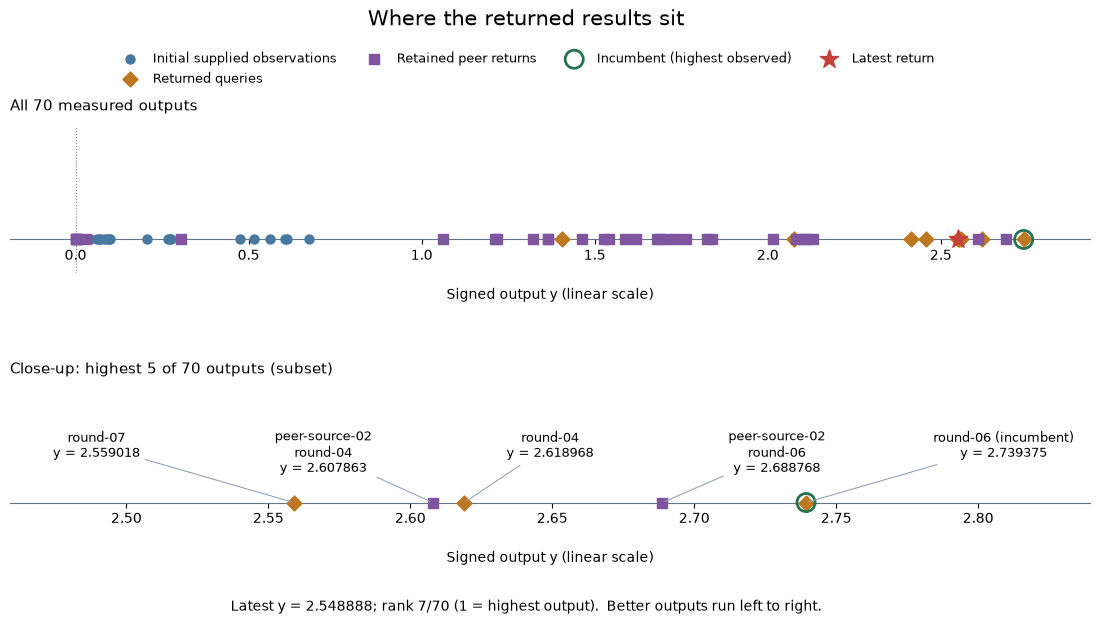

In [4]:
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_output_review, plot_round_progress, plot_input_profiles,
)

prepared = prepare_weekly_observation_review(review, history=official_data)
latest = prepared["latest"]
latest_official_rank = int((official_data.y > latest.y).sum()) + 1
latest_cohort_rank = int((review["data"].y > latest.y).sum()) + 1
display(pd.Series({"Round 8 return": latest.y, "Rank among official observations": latest_official_rank,
    "Rank in the full snapshot": latest_cohort_rank, "Best official score": official_data.y.max(),
    "Best published peer score": peer_data.y.max()}))
display(plot_output_review(review, save_to=FIGURES / "observed-output-review.png"))


## Official progress

The running maximum follows the eight official returns.

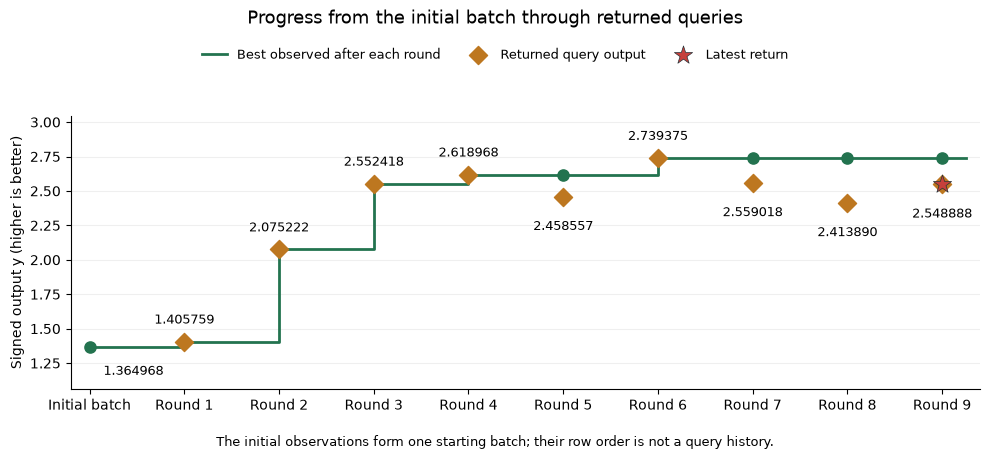

,returned_y,best_y,change_vs_prior_best
stage,,,
Initial batch,NaN,1.364968,NaN
Round 1,1.405759,1.405759,0.040791
Round 2,2.075222,2.075222,0.669463
Round 3,2.552418,2.552418,0.477196
Round 4,2.618968,2.618968,0.066551
Round 5,2.458557,2.618968,-0.160411
Round 6,2.739375,2.739375,0.120407
Round 7,2.559018,2.739375,-0.180357
Round 8,2.413890,2.739375,-0.325485


In [5]:
display(plot_round_progress(prepared["progress"], save_to=FIGURES / "official-progress.png"))
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]])


## Strongest measured input profiles

Colour encodes input settings on a common 0–1 scale.

,rank,observation_id,x1,x2,x3,x4,x5,x6,y
35,1,round-06,0.000000,0.135108,0.370684,0.306265,0.311144,0.649736,2.739375
69,2,peer-source-02-round-06,0.154047,0.257312,0.219209,0.266136,0.307656,0.729736,2.688768
33,3,round-04,0.002902,0.196293,0.424115,0.271557,0.287658,0.746916,2.618968
43,4,peer-source-02-round-04,0.174163,0.270107,0.182087,0.259510,0.282083,0.718177,2.607863
36,5,round-07,0.000000,0.135660,0.364055,0.203076,0.342712,0.663441,2.559018


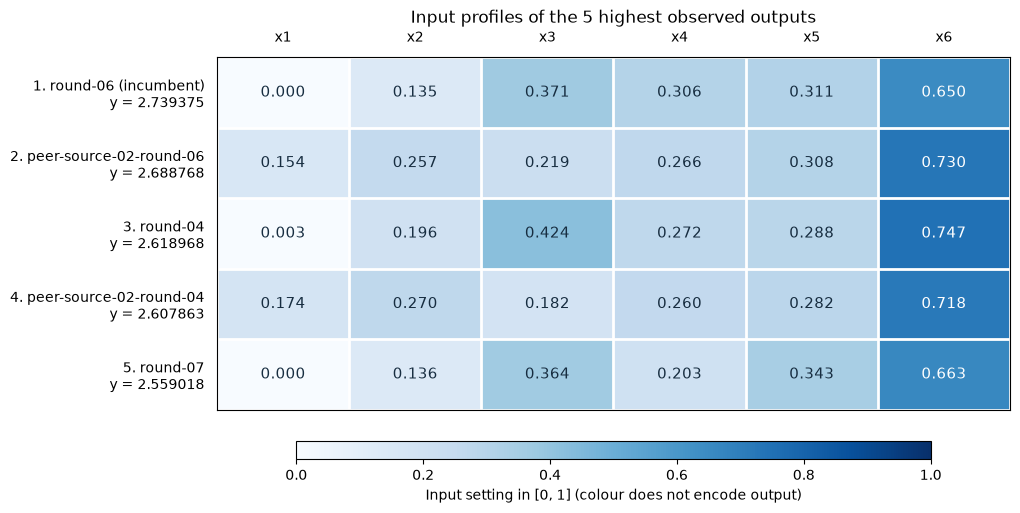

In [6]:
display(prepared["strongest"][["rank", "observation_id", *INPUT_COLUMNS, "y"]])
display(plot_input_profiles(prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=latest.observation_id, incumbent_id=prepared["incumbent"].observation_id,
    save_to=FIGURES / "strongest-input-profiles.png"))


In [7]:
summary = dict(function=FUNCTION_NUMBER, intake_date="2026-11-25",
    official_rows=intake["official"], peer_rows=intake["peer"], new_peer_rows=intake["new_peer"],
    latest_output=float(latest.y), latest_official_rank=latest_official_rank,
    latest_cohort_rank=latest_cohort_rank, official_best=float(official_data.y.max()),
    peer_best=float(peer_data.y.max()), best_peer_point=intake["peer_best_point"],
    official_snapshot_sha256=intake["official_sha256"], pooled_snapshot_sha256=intake["sha256"])
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "observation-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 7,
  "intake_date": "2026-11-25",
  "official_rows": 39,
  "peer_rows": 31,
  "new_peer_rows": 3,
  "latest_output": 2.548887833541816,
  "latest_official_rank": 5,
  "latest_cohort_rank": 7,
  "official_best": 2.7393751180039905,
  "peer_best": 2.688767533788612,
  "best_peer_point": [
    0.154047,
    0.257312,
    0.219209,
    0.266136,
    0.307656,
    0.729736
  ],
  "official_snapshot_sha256": "3873c40d37b7af8270da30ff965997f4d8ccf54caedaa7842233b46442657041",
  "pooled_snapshot_sha256": "3ce79fbc6b2ce8b3038d3d4d443bdbb2f208054ddf659464edf887fcffa50962"
}


## Preprocessing and validation diagnostics

Compare the middle half of each coordinate distribution and the empirical score distributions for official and published peer observations. Repeated groups use the rounded portal input across all coordinates. A peer at the same portal point as an official hold-out is withheld during validation. The model study tests median aggregation of training repeats and a higher assumed peer noise level. [Modelling experiments](model_predictions.ipynb#extended-cohort-surrogate-study)

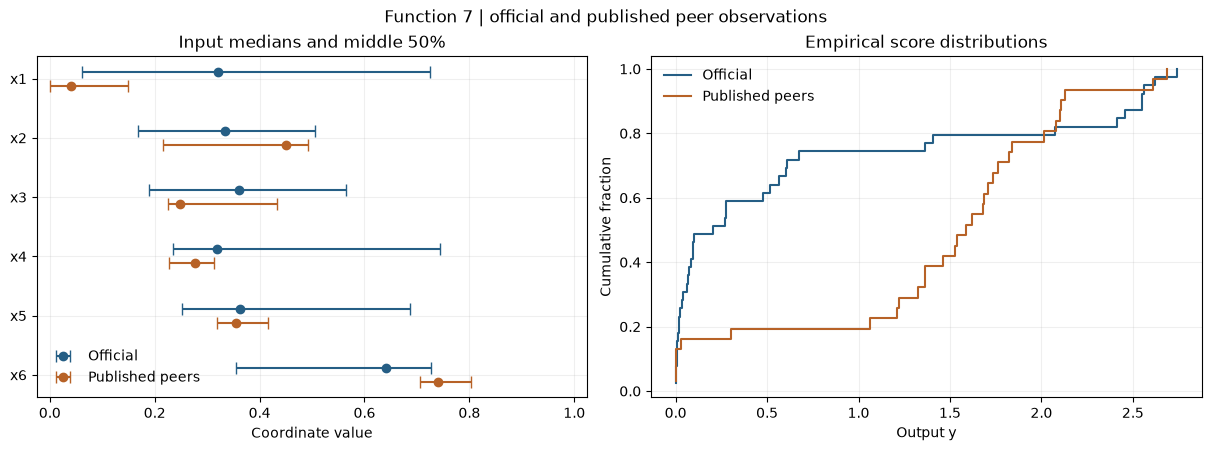

,scope,rows,rows_on_portal_boundary,score_median
0,Official,39,5,0.206310
1,Published peers,31,9,1.587444


portal_input_groups                 69.000000
repeated_input_groups                1.000000
peer_rows_matching_official          1.000000
median_peer_to_official_distance     0.205717
dtype: float64

In [8]:
from cohort_surrogate_plots import cohort_data_diagnostics

official_scores = official_data.y.to_numpy(dtype=float)
peer_scores = peer_data.y.to_numpy(dtype=float)
label = "Output y"
if FUNCTION_NUMBER == 1:
    function_helpers = STAGE / "notebooks/Function_1/FunctionSpecificShared"
    if str(function_helpers) not in sys.path:
        sys.path.insert(0, str(function_helpers))
    from function_1_model_helpers import signed_log
    official_scores = signed_log(official_scores, scale=1e-200)
    peer_scores = signed_log(peer_scores, scale=1e-200)
    label = "Signed-log height h"
diagnostics, distribution = cohort_data_diagnostics(review, official_scores, peer_scores,
    title=f"Function {FUNCTION_NUMBER} | official and published peer observations",
    target_label=label, save_to=FIGURES / "cohort-data-diagnostics.png")
display(distribution)
display(pd.DataFrame(diagnostics["by_scope"]))
display(pd.Series({key: value for key, value in diagnostics.items() if key != "by_scope"}))


### Interpreting the diagnostics

The score and input summaries compare different collections of queried points. Peer round numbers are local to their sources. The official timeline above uses the confirmed email returns.